# Notebook 02 — Binomial Tree & Monte Carlo Convergence Study

**Goal:** Price the exact same option using three independent methods—Closed-Form Black–Scholes, the Cox–Ross–Rubinstein (CRR) Binomial Tree, and Exact-Step Monte Carlo—and verify their theoretical convergence rates:
1. **CRR Binomial Tree:** $\mathcal{O}(1/N)$ convergence with sawtooth oscillation as terminal nodes shift across the strike $K$.
2. **Monte Carlo Simulation:** $\mathcal{O}(n^{-1/2})$ convergence governed by the Central Limit Theorem, plus variance reduction via **Antithetic Variates** and **Control Variates**.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import matplotlib.pyplot as plt
from src.black_scholes import bs_price, bs_greeks
from src.binomial import crr_price
from src.monte_carlo import mc_price, mc_price_cv

# Reference Parameters
S, K, T, r, sigma, q = 100.0, 105.0, 0.5, 0.03, 0.20, 0.0
TRUE_CALL = bs_price(S, K, T, r, sigma, q, kind="call")
print(f"Reference Black-Scholes Call Price: {TRUE_CALL:.6f}")

Reference Black-Scholes Call Price: 4.178300


In [2]:
# Part 1: CRR Binomial Tree Convergence (N = 10 to 2000) and Oscillation Damping
n_grid = np.arange(10, 2005, 10)
tree_errors = np.array([abs(crr_price(S, K, T, r, sigma, N=int(n)) - TRUE_CALL) for n in n_grid])

# Averaging adjacent N and N+1 steps damps the sawtooth oscillation
avg_errors = np.array([
    abs(0.5 * (crr_price(S, K, T, r, sigma, N=int(n)) + crr_price(S, K, T, r, sigma, N=int(n) + 1)) - TRUE_CALL)
    for n in n_grid
])

tree_slope, _ = np.polyfit(np.log(n_grid), np.log(tree_errors), 1)
print(f"CRR Tree Log-Log Slope: {tree_slope:.3f} (Theoretical: -1.00)")

# Compare first-step tree Delta with analytical Black-Scholes Delta
N_delta = 1000
dt = T / N_delta
u = np.exp(sigma * np.sqrt(dt))
d = 1.0 / u
v_up = crr_price(S * u, K, T - dt, r, sigma, N=N_delta - 1)
v_dn = crr_price(S * d, K, T - dt, r, sigma, N=N_delta - 1)
tree_delta = (v_up - v_dn) / (S * u - S * d)
bs_delta = bs_greeks(S, K, T, r, sigma, q, kind="call")["delta"]
print(f"Tree Delta (N=1000): {tree_delta:.6f} | BS Delta: {bs_delta:.6f}")

CRR Tree Log-Log Slope: -0.998 (Theoretical: -1.00)
Tree Delta (N=1000): 0.433189 | BS Delta: 0.433204


## Why the Tree Oscillates & American Early Exercise
* **Sawtooth Oscillation:** Because terminal tree nodes sit at discrete points $S_0 u^j d^{N-j}$, increasing $N$ changes where the strike $K$ falls between the two nearest nodes (non-linearity error at the kink of $\max(S_T - K, 0)$). Averaging $N$ and $N+1$ smooths this kink error.
* **American Options:**
  * Without dividends ($q = 0$), an American call is never exercised early because holding preserves time value and delays paying the strike $K$. Thus $\text{American Call} = \text{European Call}$.
  * An American put commands a positive **early-exercise premium** when deep in the money, and a high dividend yield ($q > 0$) can make early exercise optimal for an American call.

No-Dividend Call (q=0) -> European: 4.178042 | American: 4.178042
Dividend Call (q=0.06) -> European: 18.651456 | American: 20.463792


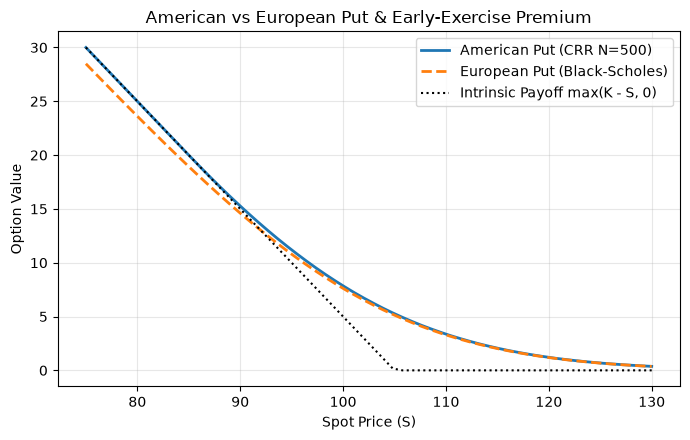

In [3]:
# Part 2: American vs European Checks & Early-Exercise Put Plot
euro_call = crr_price(S, K, T, r, sigma, N=500, q=0.0, kind="call", american=False)
amer_call = crr_price(S, K, T, r, sigma, N=500, q=0.0, kind="call", american=True)
print(f"No-Dividend Call (q=0) -> European: {euro_call:.6f} | American: {amer_call:.6f}")

# With positive dividend yield q = 0.06, American call exceeds European call
euro_call_div = crr_price(120.0, 100.0, 1.0, 0.03, 0.20, N=500, q=0.06, kind="call", american=False)
amer_call_div = crr_price(120.0, 100.0, 1.0, 0.03, 0.20, N=500, q=0.06, kind="call", american=True)
print(f"Dividend Call (q=0.06) -> European: {euro_call_div:.6f} | American: {amer_call_div:.6f}")

# Plot American Put vs European Put across Spot S
spots = np.linspace(75, 130, 60)
euro_puts = [bs_price(s, K, T, r, sigma, q, kind="put") for s in spots]
amer_puts = [crr_price(s, K, T, r, sigma, N=500, q=q, kind="put", american=True) for s in spots]
intrinsic = np.maximum(K - spots, 0.0)

plt.figure(figsize=(7, 4.5))
plt.plot(spots, amer_puts, label="American Put (CRR N=500)", lw=2)
plt.plot(spots, euro_puts, "--", label="European Put (Black-Scholes)", lw=2)
plt.plot(spots, intrinsic, "k:", label="Intrinsic Payoff max(K - S, 0)")
plt.title("American vs European Put & Early-Exercise Premium")
plt.xlabel("Spot Price (S)")
plt.ylabel("Option Value")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(Path.cwd().parent / "report" / "figures" / "02_american_put.png", dpi=200)
plt.show()

In [4]:
# Part 3: Monte Carlo Convergence Across Sample Sizes and 50 Independent Seeds
mc_counts = np.array([100, 500, 1_000, 5_000, 10_000, 50_000, 100_000, 500_000])
n_seeds = 50
rmse_plain, rmse_anti, rmse_cv = [], [], []

for n in mc_counts:
    sq_err_p, sq_err_a, sq_err_c = [], [], []
    for s_idx in range(n_seeds):
        p_est, _ = mc_price(S, K, T, r, sigma, q, n=int(n), antithetic=False, seed=s_idx)
        a_est, _ = mc_price(S, K, T, r, sigma, q, n=int(n), antithetic=True, seed=s_idx)
        c_est, _ = mc_price_cv(S, K, T, r, sigma, q, n=int(n), seed=s_idx)
        sq_err_p.append((p_est - TRUE_CALL) ** 2)
        sq_err_a.append((a_est - TRUE_CALL) ** 2)
        sq_err_c.append((c_est - TRUE_CALL) ** 2)

    rmse_plain.append(np.sqrt(np.mean(sq_err_p)))
    rmse_anti.append(np.sqrt(np.mean(sq_err_a)))
    rmse_cv.append(np.sqrt(np.mean(sq_err_c)))

mc_slope, _ = np.polyfit(np.log(mc_counts), np.log(rmse_plain), 1)
print(f"Monte Carlo Log-Log Slope: {mc_slope:.3f} (Theoretical: -0.50)\n")

# Variance Reduction Summary at n = 200,000
p_val, p_se = mc_price(S, K, T, r, sigma, q, n=200_000, antithetic=False, seed=42)
a_val, a_se = mc_price(S, K, T, r, sigma, q, n=200_000, antithetic=True, seed=42)
c_val, c_se = mc_price_cv(S, K, T, r, sigma, q, n=200_000, seed=42)

print(f"{'Method':<22} | {'Price':<10} | {'Std Error':<10} | {'95% CI':<22} | {'Var Reduction'}")
print("-" * 80)
for name, val, se in [
    ("Plain Monte Carlo", p_val, p_se),
    ("Antithetic Variates", a_val, a_se),
    ("Control Variate", c_val, c_se),
]:
    ci_l, ci_u = val - 1.96 * se, val + 1.96 * se
    vr = (p_se / se) ** 2
    print(f"{name:<22} | {val:<10.5f} | {se:<10.5f} | [{ci_l:.4f}, {ci_u:.4f}] | {vr:.2f}x")

Monte Carlo Log-Log Slope: -0.508 (Theoretical: -0.50)

Method                 | Price      | Std Error  | 95% CI                 | Var Reduction
--------------------------------------------------------------------------------
Plain Monte Carlo      | 4.19225    | 0.01765    | [4.1576, 4.2268] | 1.00x
Antithetic Variates    | 4.19211    | 0.01054    | [4.1715, 4.2128] | 2.81x
Control Variate        | 4.19441    | 0.00964    | [4.1755, 4.2133] | 3.35x


In [5]:
# Part 4: 95% Confidence Interval Empirical Coverage Check Across 100 Seeds
n_coverage_seeds = 100
inside_ci = 0
for s_idx in range(n_coverage_seeds):
    est, se = mc_price(S, K, T, r, sigma, q, n=50_000, antithetic=False, seed=s_idx)
    if abs(est - TRUE_CALL) <= 1.96 * se:
        inside_ci += 1

coverage_pct = 100.0 * inside_ci / n_coverage_seeds
print(f"95% CI Coverage over {n_coverage_seeds} seeds: {coverage_pct:.1f}% (Expected ~95%)")

95% CI Coverage over 100 seeds: 93.0% (Expected ~95%)


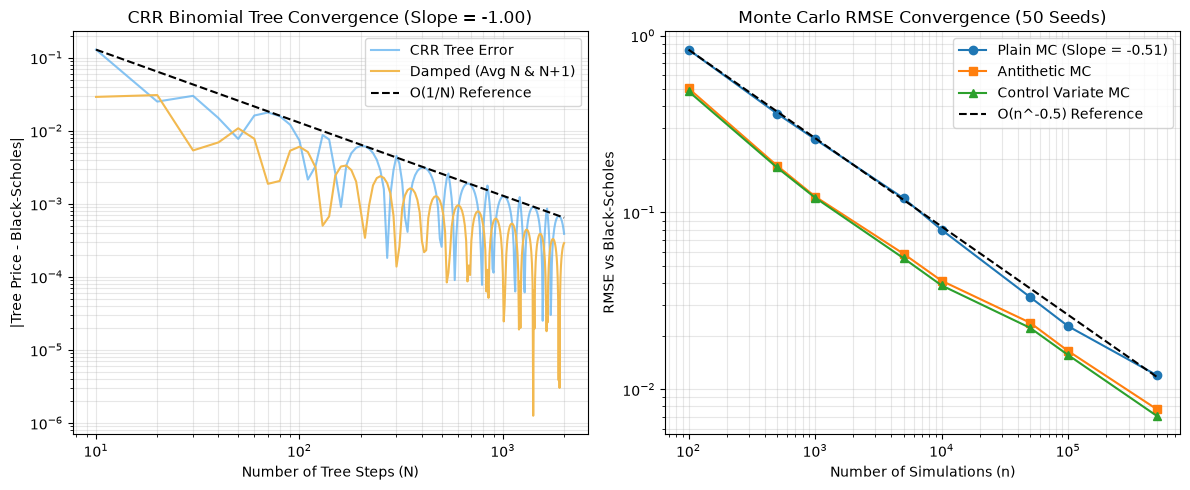

In [6]:
# Part 5: Save Headline Convergence Plot (Tree O(1/N) and Monte Carlo O(n^-0.5))
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].loglog(n_grid, tree_errors, color="#5eb0ef", alpha=0.75, label="CRR Tree Error")
axes[0].loglog(n_grid, avg_errors, color="#f2b950", lw=1.5, label="Damped (Avg N & N+1)")
axes[0].loglog(n_grid, tree_errors[0] * (n_grid[0] / n_grid), "k--", label="O(1/N) Reference")
axes[0].set_title(f"CRR Binomial Tree Convergence (Slope = {tree_slope:.2f})")
axes[0].set_xlabel("Number of Tree Steps (N)")
axes[0].set_ylabel("|Tree Price - Black-Scholes|")
axes[0].legend()
axes[0].grid(True, which="both", alpha=0.3)

axes[1].loglog(mc_counts, rmse_plain, "o-", label=f"Plain MC (Slope = {mc_slope:.2f})")
axes[1].loglog(mc_counts, rmse_anti, "s-", label="Antithetic MC")
axes[1].loglog(mc_counts, rmse_cv, "^-", label="Control Variate MC")
axes[1].loglog(mc_counts, rmse_plain[0] * np.sqrt(mc_counts[0] / mc_counts), "k--", label="O(n^-0.5) Reference")
axes[1].set_title("Monte Carlo RMSE Convergence (50 Seeds)")
axes[1].set_xlabel("Number of Simulations (n)")
axes[1].set_ylabel("RMSE vs Black-Scholes")
axes[1].legend()
axes[1].grid(True, which="both", alpha=0.3)

plt.tight_layout()
plt.savefig(Path.cwd().parent / "report" / "figures" / "02_convergence_study.png", dpi=200)
plt.show()